<a href="https://colab.research.google.com/github/Parth-22k/ML-Lab/blob/main/Exp5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Class names:
['setosa' 'versicolor' 'virginica']

Dataset shape:
(150, 4)

Accuracy = 0.9666666666666667

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


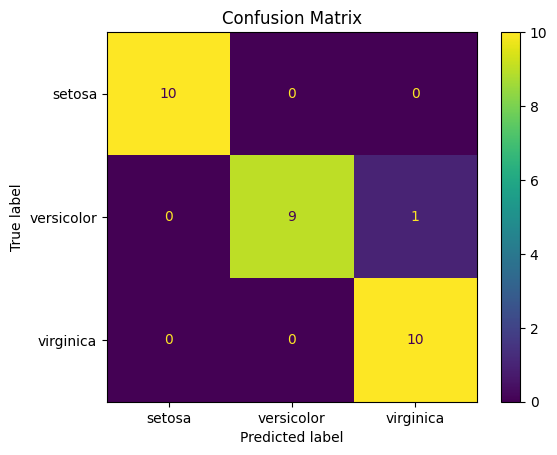

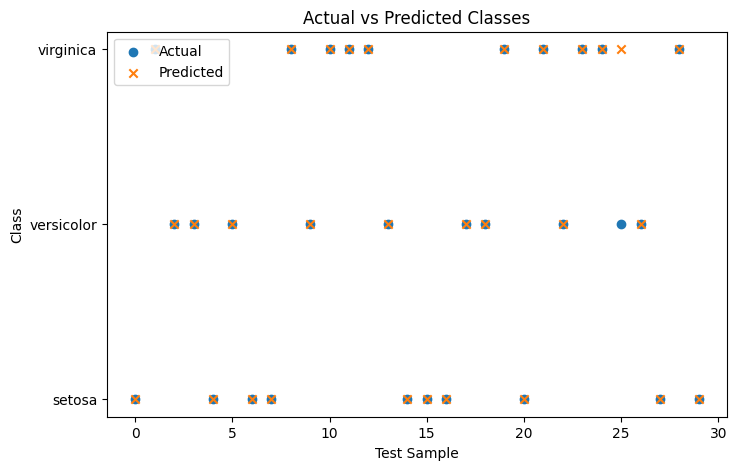


Probabilities of first 5 test samples:
[[9.85317118e-01 1.46828357e-02 4.62322265e-08]
 [1.37654815e-03 3.90936942e-01 6.07686509e-01]
 [1.86889921e-01 8.08906904e-01 4.20317527e-03]
 [1.55862011e-01 8.39907880e-01 4.23010948e-03]
 [9.88257472e-01 1.17424923e-02 3.53991130e-08]]


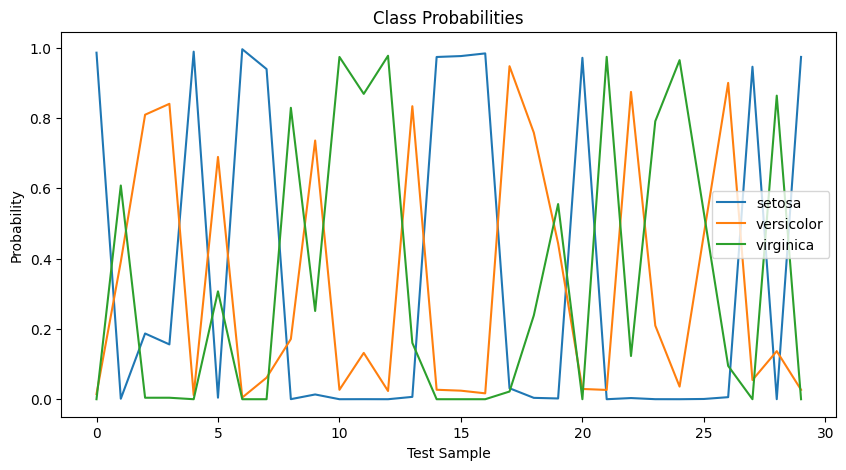

In [ ]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# --------------------------------------------------
# 1. Load Dataset
# --------------------------------------------------

iris = load_iris()

X = iris.data
y = iris.target

print("Feature names:")
print(iris.feature_names)

print("\nClass names:")
print(iris.target_names)

print("\nDataset shape:")
print(X.shape)


# --------------------------------------------------
# 2. Split Dataset
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# --------------------------------------------------
# 3. Create Logistic Regression Model
# --------------------------------------------------

model = LogisticRegression(
    max_iter=200
)


# --------------------------------------------------
# 4. Train Model
# --------------------------------------------------

model.fit(X_train, y_train)


# --------------------------------------------------
# 5. Prediction
# --------------------------------------------------

y_pred = model.predict(X_test)


# --------------------------------------------------
# 6. Accuracy
# --------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy =", accuracy)


# --------------------------------------------------
# 7. Confusion Matrix
# --------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()


# --------------------------------------------------
# 8. Actual vs Predicted Graph
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    range(len(y_test)),
    y_test,
    label="Actual",
    marker="o"
)

plt.scatter(
    range(len(y_pred)),
    y_pred,
    label="Predicted",
    marker="x"
)

plt.xlabel("Test Sample")
plt.ylabel("Class")

plt.yticks(
    [0, 1, 2],
    iris.target_names
)

plt.title("Actual vs Predicted Classes")

plt.legend()

plt.show()


# --------------------------------------------------
# 9. Probability Prediction
# --------------------------------------------------

probabilities = model.predict_proba(X_test)

print("\nProbabilities of first 5 test samples:")

print(probabilities[:5])


# --------------------------------------------------
# 10. Probability Graph
# --------------------------------------------------

plt.figure(figsize=(10, 5))

for i in range(3):
    plt.plot(
        range(len(probabilities)),
        probabilities[:, i],
        label=iris.target_names[i]
    )

plt.xlabel("Test Sample")
plt.ylabel("Probability")

plt.title("Class Probabilities")

plt.legend()

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

df = pd.read_csv(
    '/content/drive/MyDrive/ML/energy_efficiency_data.csv'
)

print(df.head())
print(df.shape)
print(df.columns)
df['Heating_Class']=pd.qcut(df['Heating_Load'],q=3,Labels=['High','Midium','Low'])

   Relative_Compactness  Surface_Area  Wall_Area  Roof_Area  Overall_Height  \
0                  0.98         514.5      294.0     110.25             7.0   
1                  0.98         514.5      294.0     110.25             7.0   
2                  0.98         514.5      294.0     110.25             7.0   
3                  0.98         514.5      294.0     110.25             7.0   
4                  0.90         563.5      318.5     122.50             7.0   

   Orientation  Glazing_Area  Glazing_Area_Distribution  Heating_Load  \
0            2           0.0                          0         15.55   
1            3           0.0                          0         15.55   
2            4           0.0                          0         15.55   
3            5           0.0                          0         15.55   
4            2           0.0                          0         20.84   

   Cooling_Load  
0         21.33  
1         21.33  
2         21.33  
3         21.3